# 1. Entendimento do Problema / Contexto de Negócio

**Problema a ser resolvido:** a empresa enfrenta dificuldade na fidelização dos clientes, com um número elevado de cancelamentos.

**Solução:** desenvolver um modelo preditivo para identificar os clientes mais propensos a cancelar, permitindo a criação de campanhas e estratégias de fidelização.

**Quem vai utilizar a solução:** times de dados, marketing e gestão.

**Resultado mais prejudicial:** falso negativo (deixar de identificar um cliente que realmente irá cancelar).


# 2. Coleta e Carregamento dos Dados


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE 
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report , roc_auc_score , confusion_matrix , ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier


pd.set_option('display.max_columns', None)

df = pd.read_csv('data/WA_Fn-UseC_-Telco-Customer-Churn.csv')

# 3. EDA (Análise Exploratória dos Dados)

In [2]:
print(df.shape)
print()
print(df.dtypes)

(7043, 21)

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


In [3]:
df.describe(include= 'all')

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## Auditoria de Qualidade dos Dados

In [8]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

Não foram encontrados registros duplicados. Porém, foram identificados 11 valores ausentes na coluna TotalCharges.

Verificando o balanceamento da variável alvo (Churn).

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


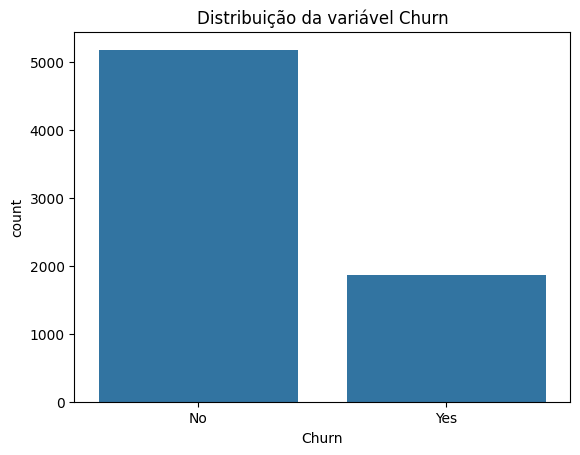

In [10]:
print(df['Churn'].value_counts())
print((df['Churn'].value_counts(normalize= True)*100).round(2))

sns.countplot(data= df , x='Churn')
plt.title("Distribuição da variável Churn")
plt.show()

### Análise Univariada

In [11]:
numericas = [c for c in df.select_dtypes(include = ['int64', 'float64']).columns if c not in ['SeniorCitizen']]
print(numericas)

['tenure', 'MonthlyCharges', 'TotalCharges']


In [12]:
df[numericas].skew()

tenure            0.239540
MonthlyCharges   -0.220524
TotalCharges      0.961642
dtype: float64

In [13]:
df[numericas].kurt()

tenure           -1.387372
MonthlyCharges   -1.257260
TotalCharges     -0.231799
dtype: float64

In [14]:
categoricas = [c for c in df.select_dtypes(include = ['object']).columns if c not in ('Churn', 'customerID')]

print(categoricas)

['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


/tmp/ipykernel_544/3503560682.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categoricas = [c for c in df.select_dtypes(include = ['object']).columns if c not in ('Churn', 'customerID')]


In [15]:
for c in categoricas :
    print(df[c].value_counts())
    print()


gender
Male      3555
Female    3488
Name: count, dtype: int64

Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents
No     4933
Yes    2110
Name: count, dtype: int64



PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64

TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64

StreamingTV
No                     2810
Yes                    2707
No internet service    1526
Name: count, dtype: int64

StreamingMovies
No                     2785
Yes                    2732
No internet service  

### Verificação de Outliers (Método IQR)

In [16]:
outliers_resumo = {}
for col in numericas :
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers =df [(df[col] < limite_inferior) | (df[col] > limite_superior)]
    outliers_resumo[col] = outliers.shape[0]

pd.Series(outliers_resumo , name = 'qtd_outliers')

tenure            0
MonthlyCharges    0
TotalCharges      0
Name: qtd_outliers, dtype: int64

### Análise Bivariada


tenure
Churn
No     38.0
Yes    10.0
Name: tenure, dtype: float64


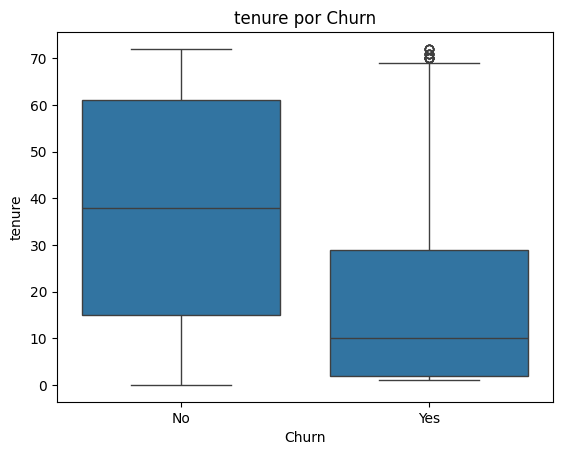


MonthlyCharges
Churn
No     64.425
Yes    79.650
Name: MonthlyCharges, dtype: float64


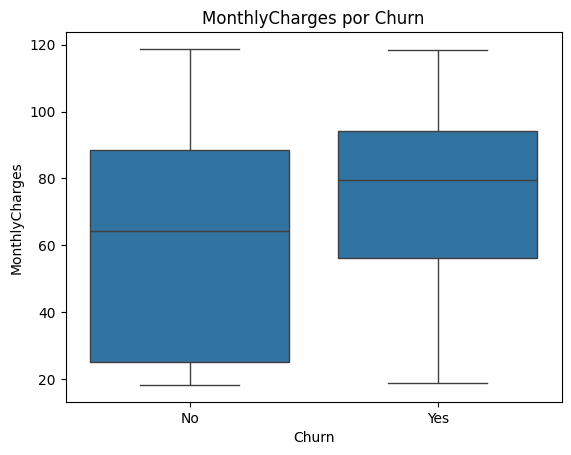


TotalCharges
Churn
No     1683.60
Yes     703.55
Name: TotalCharges, dtype: float64


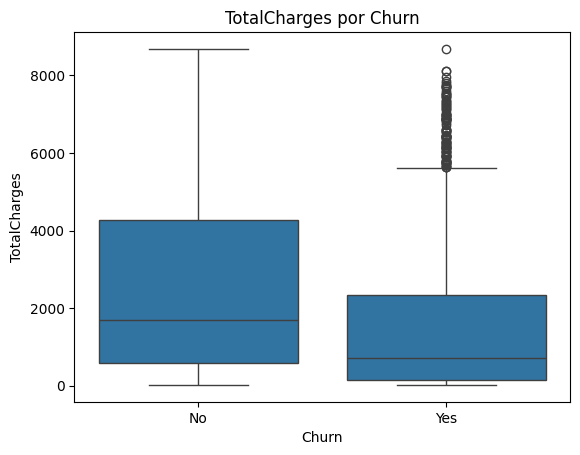

In [17]:
for col in numericas:
    print(f'\n{col}')
    print(df.groupby('Churn')[col].median())

    sns.boxplot(data = df , x= 'Churn' , y = col)
    plt.title(f'{col} por Churn')
    plt.show()


gender
Churn         No       Yes
gender                    
Female  0.730791  0.269209
Male    0.738397  0.261603


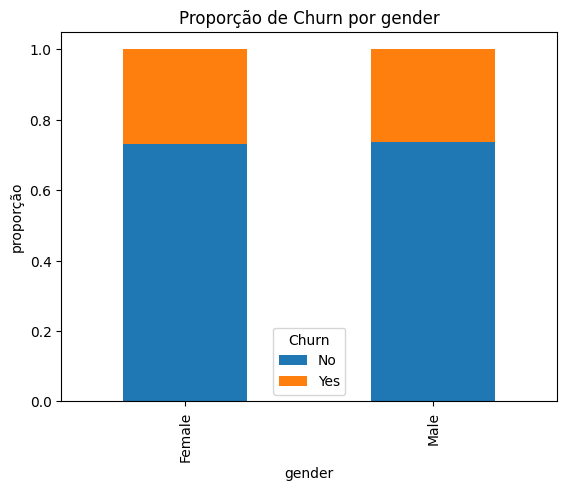


Partner
Churn          No       Yes
Partner                    
No       0.670420  0.329580
Yes      0.803351  0.196649


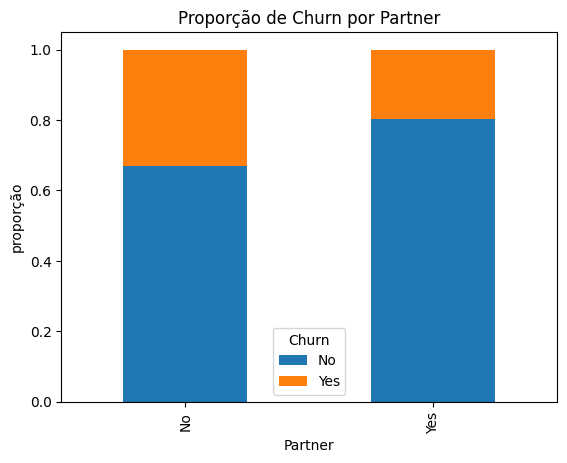


Dependents
Churn             No       Yes
Dependents                    
No          0.687209  0.312791
Yes         0.845498  0.154502


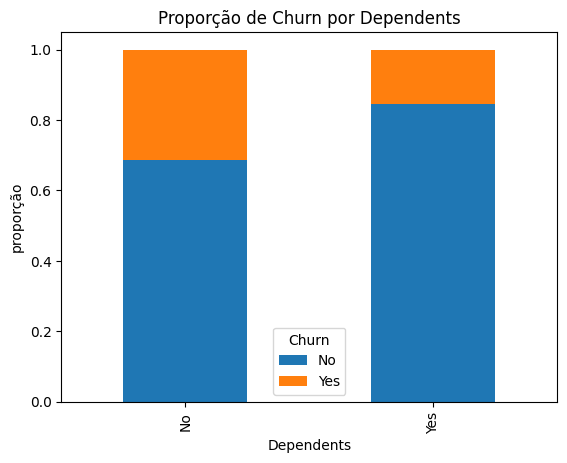


PhoneService
Churn               No       Yes
PhoneService                    
No            0.750733  0.249267
Yes           0.732904  0.267096


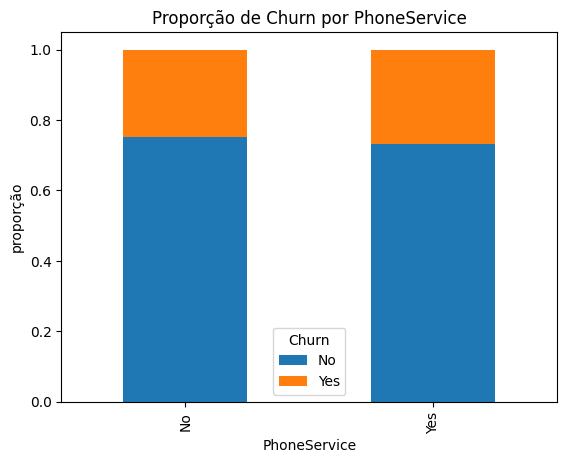


MultipleLines
Churn                   No       Yes
MultipleLines                       
No                0.749558  0.250442
No phone service  0.750733  0.249267
Yes               0.713901  0.286099


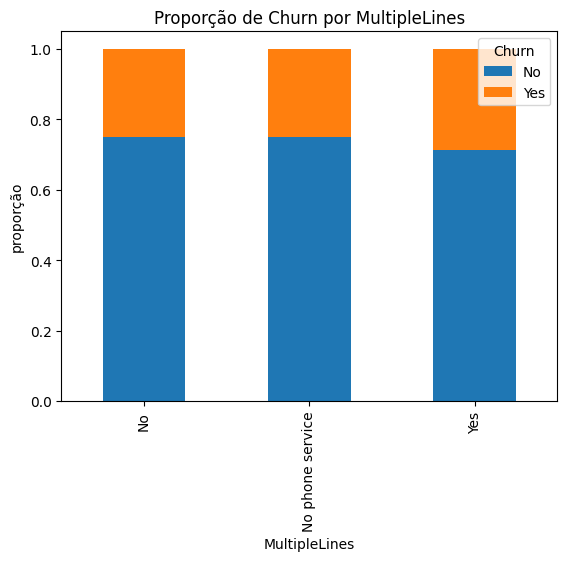


InternetService
Churn                  No       Yes
InternetService                    
DSL              0.810409  0.189591
Fiber optic      0.581072  0.418928
No               0.925950  0.074050


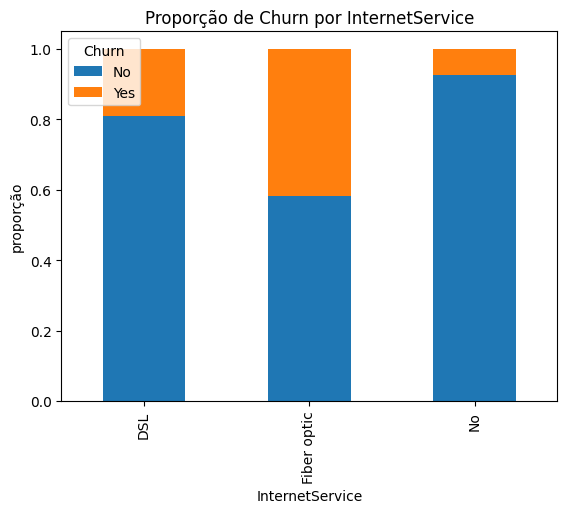


OnlineSecurity
Churn                      No       Yes
OnlineSecurity                         
No                   0.582333  0.417667
No internet service  0.925950  0.074050
Yes                  0.853888  0.146112


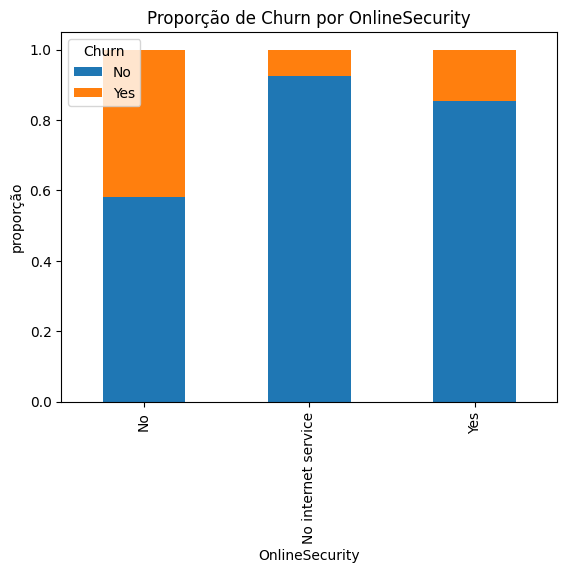


OnlineBackup
Churn                      No       Yes
OnlineBackup                           
No                   0.600712  0.399288
No internet service  0.925950  0.074050
Yes                  0.784685  0.215315


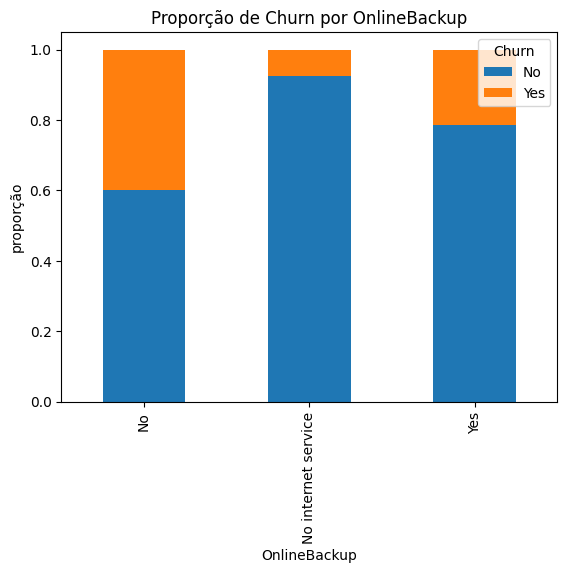


DeviceProtection
Churn                      No       Yes
DeviceProtection                       
No                   0.608724  0.391276
No internet service  0.925950  0.074050
Yes                  0.774979  0.225021


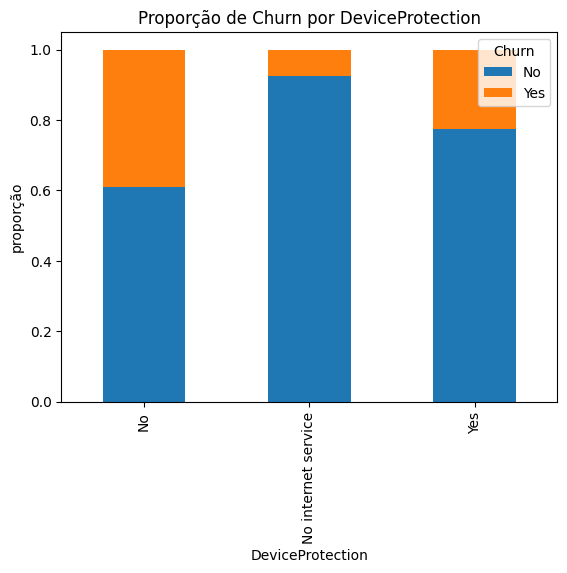


TechSupport
Churn                      No       Yes
TechSupport                            
No                   0.583645  0.416355
No internet service  0.925950  0.074050
Yes                  0.848337  0.151663


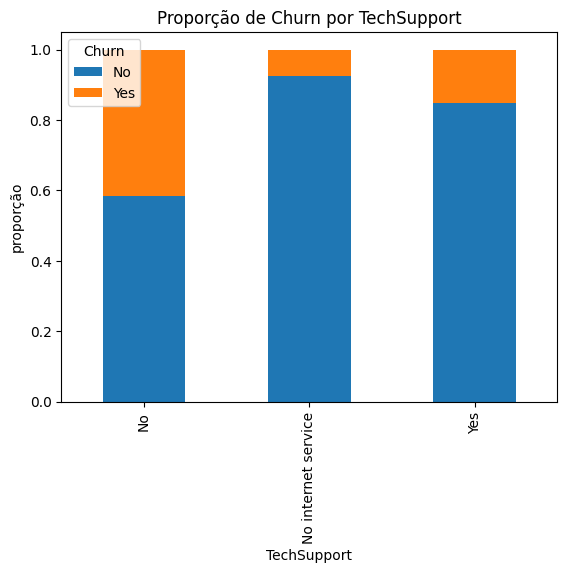


StreamingTV
Churn                      No       Yes
StreamingTV                            
No                   0.664769  0.335231
No internet service  0.925950  0.074050
Yes                  0.699298  0.300702


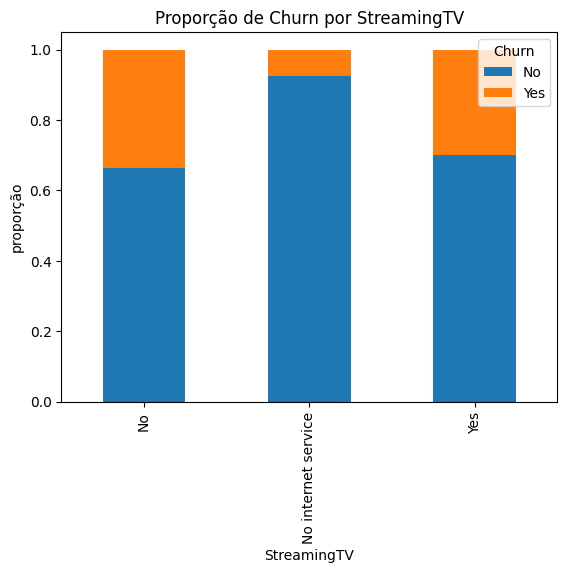


StreamingMovies
Churn                      No       Yes
StreamingMovies                        
No                   0.663196  0.336804
No internet service  0.925950  0.074050
Yes                  0.700586  0.299414


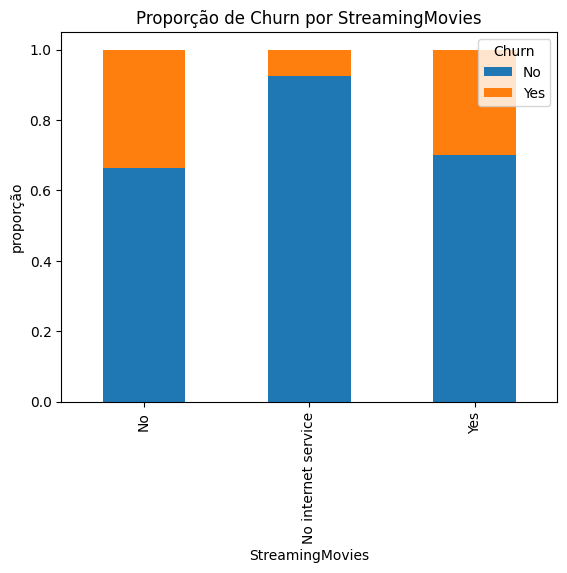


Contract
Churn                 No       Yes
Contract                          
Month-to-month  0.572903  0.427097
One year        0.887305  0.112695
Two year        0.971681  0.028319


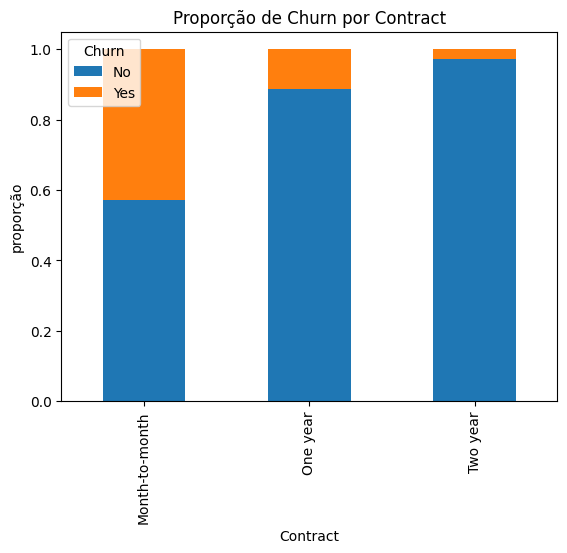


PaperlessBilling
Churn                   No       Yes
PaperlessBilling                    
No                0.836699  0.163301
Yes               0.664349  0.335651


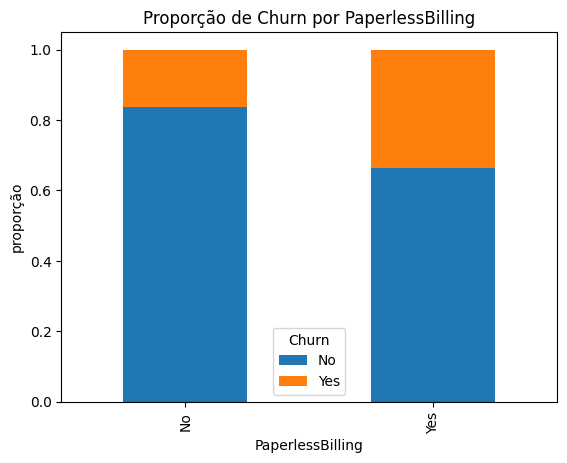


PaymentMethod
Churn                            No       Yes
PaymentMethod                                
Bank transfer (automatic)  0.832902  0.167098
Credit card (automatic)    0.847569  0.152431
Electronic check           0.547146  0.452854
Mailed check               0.808933  0.191067


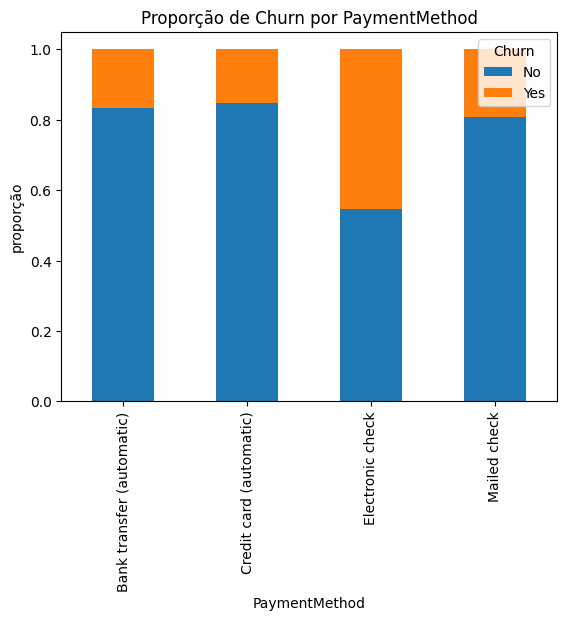

In [18]:
for col in categoricas:
    tab = pd.crosstab(df[col], df['Churn'], normalize = 'index')
    print(f'\n{col}')
    print(tab)

    tab.plot(kind = 'bar', stacked = True)
    plt.title(f'Proporção de Churn por {col}')
    plt.ylabel('proporção')
    plt.show()


### Insights da EDA

* A base possui 7043 clientes e 21 colunas, sem registros duplicados.
* A variável alvo está desbalanceada: 73,46% dos clientes não cancelam (No) e 26,54% cancelam (Yes).
* A coluna TotalCharges apresentou 11 valores ausentes após a conversão para numérico, todos referentes a clientes com tenure igual a 0 (clientes muito novos).
* Não foram identificados outliers relevantes nas variáveis numéricas pelo método do IQR.
* TotalCharges apresenta assimetria positiva (skew próximo de 0,96), indicando concentração de clientes com valores acumulados baixos.
* Clientes que cancelam têm tempo de permanência (tenure) mediano bem menor (10 meses contra 38 meses dos que permanecem), mensalidade (MonthlyCharges) mais alta (79,65 contra 64,43) e gasto total (TotalCharges) menor. Ou seja, cancelam cedo, pagando mais por mês.
* O tipo de contrato é um forte diferenciador: contratos mensais (Month to month) têm taxa de churn de 42,7%, contra 11,3% nos contratos de 1 ano e 2,8% nos de 2 anos.
* Clientes com internet via fibra ótica (Fiber optic) cancelam mais (41,9%) do que os de DSL (18,9%) e os sem internet (7,4%).
* A ausência de serviços adicionais como OnlineSecurity, TechSupport, OnlineBackup e DeviceProtection está associada a taxas de churn mais altas.
* O método de pagamento Electronic check concentra a maior taxa de churn (45,3%), bem acima dos demais métodos (entre 15% e 19%).
* Clientes com PaperlessBilling ativo cancelam mais (33,6%) do que os que não usam (16,3%).
* Gênero e PhoneService têm pouca relação com o churn, pouco úteis como preditores isolados.

# 4. Pré-Processamento

Separação entre as variáveis explicativas (X) e a variável alvo Churn (y).

In [19]:
x = df.drop(columns= ['customerID', 'Churn'])
y = df['Churn']

print(x.shape , y.shape)

(7043, 19) (7043,)


Divisão entre Treino e Teste

In [20]:
x_train, x_test , y_train , y_test = train_test_split(x , y , test_size = 0.2 , stratify = y , random_state=42)

print('Formato do X , em treino:', x_train.shape, 'teste:', x_test.shape)
print()
print('Proporção do Churn no treino :')
print((y_train.value_counts(normalize = True) * 100).round(2))
print('Proporção do Churn no teste:')
print((y_test.value_counts(normalize = True) * 100).round(2))


Formato do X , em treino: (5634, 19) teste: (1409, 19)

Proporção do Churn no treino :
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64
Proporção do Churn no teste:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


Tratamento de Valores Ausentes

In [21]:
mediana_TotalCharges = x_train['TotalCharges'].median()
x_train['TotalCharges'] = x_train['TotalCharges'].fillna(mediana_TotalCharges)
x_test['TotalCharges'] = x_test['TotalCharges'].fillna(mediana_TotalCharges)

print(x_train.isnull().sum())
print()
print(x_test.isnull().sum())

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
dtype: int64

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
dtype: int64


Encoding das Variáveis Categóricas

In [22]:
x_train =pd.get_dummies(x_train,columns = ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod'] , drop_first=True )
x_test = pd.get_dummies(x_test,columns = ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod'] , drop_first=True )

y_train= y_train.map({'Yes': 1 , 'No': 0})
y_test =y_test.map({'Yes': 1, 'No': 0})

x_test = x_test.reindex(columns = x_train.columns , fill_value= 0)

x_train.head()


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3738,0,35,49.20,1701.65,True,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,False,True,False,True,False,False,False,False,True,False
3151,0,15,75.10,1151.55,True,True,True,True,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
4860,0,13,40.55,590.35,True,True,True,False,True,False,False,False,False,True,False,True,False,False,False,True,False,False,False,False,False,True,False,False,False,True
3867,0,26,73.50,1905.70,False,True,False,True,False,False,False,False,False,False,False,True,False,True,False,False,False,True,False,True,False,True,True,True,False,False
3810,0,1,44.55,44.55,True,True,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False


In [23]:
y_train.head()

3738    0
3151    0
4860    0
3867    0
3810    0
Name: Churn, dtype: int64

Padronização das Variáveis Numéricas

In [24]:
colunas_padr = ['tenure','MonthlyCharges','TotalCharges']

scaler = StandardScaler()

x_train[colunas_padr] = scaler.fit_transform(x_train[colunas_padr])
x_test[colunas_padr] = scaler.transform(x_test[colunas_padr])

x_train[colunas_padr].describe().round(3)

,tenure,MonthlyCharges,TotalCharges
count,5634.000,5634.000,5634.000
mean,-0.000,-0.000,-0.000
std,1.000,1.000,1.000
min,-1.322,-1.544,-1.002
25%,-0.956,-0.971,-0.831
50%,-0.142,0.185,-0.397
75%,0.916,0.832,0.674
max,1.608,1.786,2.803


Balanceamento do Dataset (SMOTE)

In [25]:
smote = SMOTE(random_state=42)

x_train_bal, y_train_bal = smote.fit_resample(x_train ,y_train)

### Insights do Pré-processamento

* A divisão treino e teste (80/20) manteve a proporção original do Churn em ambos os conjuntos, garantindo uma avaliação consistente.
* Os 11 valores ausentes em TotalCharges foram preenchidos com a mediana calculada apenas no treino, evitando vazamento de dados (data leakage) para o teste.
* As variáveis categóricas foram convertidas em variáveis binárias por meio de one hot encoding, com a primeira categoria de cada variável removida para evitar multicolinearidade.
* As variáveis numéricas (tenure, MonthlyCharges e TotalCharges) foram padronizadas com StandardScaler, resultando em média 0 e desvio padrão 1.
* O SMOTE foi aplicado somente no conjunto de treino para balancear as classes, mantendo o conjunto de teste com a distribuição original e assim garantindo uma avaliação realista do modelo.

## Treinamento do Modelo

In [26]:
modelo_lr = LogisticRegression(random_state=42, max_iter=1000)
modelo_lr.fit(x_train_bal, y_train_bal)

y_pred =modelo_lr.predict(x_test)
y_proba = modelo_lr.predict_proba(x_test)[:,1]

## Avaliação do Modelo

              precision    recall  f1-score   support

   Não Churn       0.88      0.74      0.81      1035
       Churn       0.50      0.71      0.59       374

    accuracy                           0.74      1409
   macro avg       0.69      0.73      0.70      1409
weighted avg       0.78      0.74      0.75      1409

ROC - AUC : 0.819


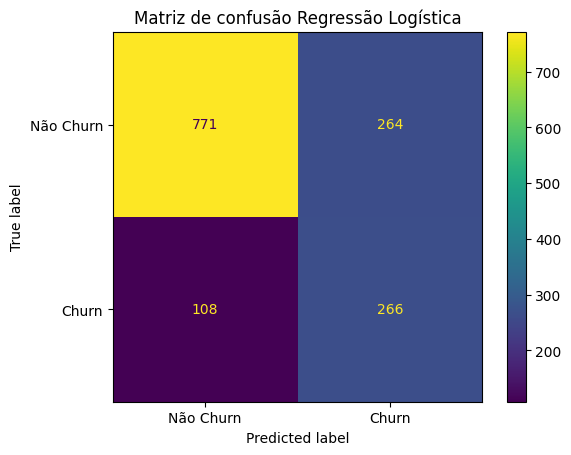

In [27]:
print(classification_report(y_test , y_pred, target_names = ['Não Churn', 'Churn']))
print('ROC - AUC :', round(roc_auc_score(y_test, y_proba), 3))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['Não Churn', 'Churn'] )
plt.title('Matriz de confusão Regressão Logística')
plt.show()


## Interpretação dos Coeficientes

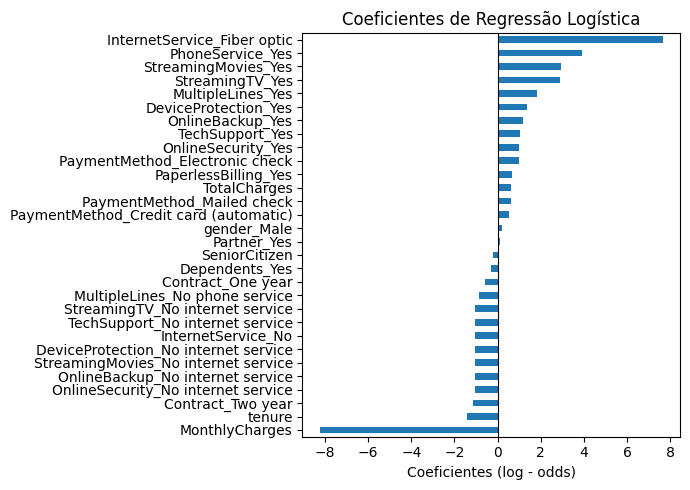

In [28]:
componentes = pd.Series(modelo_lr.coef_[0] , index= x_train.columns).sort_values()

plt.figure(figsize = (7,5))
componentes.plot(kind ='barh')
plt.title('Coeficientes de Regressão Logística')
plt.xlabel('Coeficientes (log - odds)')
plt.axvline(0 , color = 'black', linewidth = 0.8)
plt.tight_layout()
plt.show()


Utilização do Random Forest para comparar o desempenho dos modelos e escolher o que se adeque melhor as necessidade de negócio .

In [29]:
modelo_rf = RandomForestClassifier(n_estimators = 200 ,random_state=42)
modelo_rf.fit(x_train_bal,y_train_bal)


y_pred_rf = modelo_rf.predict(x_test)
y_proba_rf = modelo_rf.predict_proba(x_test)[:,1]



              precision    recall  f1-score   support

   Não Churn       0.86      0.80      0.83      1035
       Churn       0.54      0.63      0.58       374

    accuracy                           0.76      1409
   macro avg       0.70      0.72      0.70      1409
weighted avg       0.77      0.76      0.76      1409

ROC - AUC : 0.82


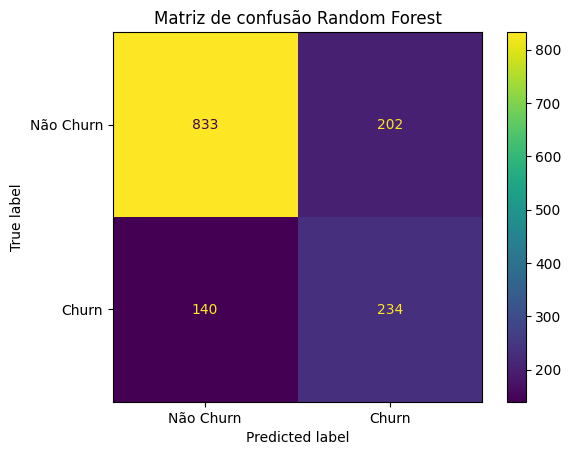

In [30]:
print(classification_report(y_test , y_pred_rf, target_names = ['Não Churn', 'Churn']))
print('ROC - AUC :', round(roc_auc_score(y_test, y_proba_rf), 3))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, display_labels=['Não Churn', 'Churn'] )
plt.title('Matriz de confusão Random Forest')
plt.show()

## Comparação entre os Modelos

In [31]:
relatorio_lr = classification_report(y_test, y_pred, target_names=['Não Churn', 'Churn'], output_dict=True)
relatorio_rf = classification_report(y_test, y_pred_rf, target_names=['Não Churn', 'Churn'], output_dict=True)

comparacao = pd.DataFrame({
    'Regressão Logística': {
        'Recall Churn': relatorio_lr['Churn']['recall'],
        'Precisão Churn': relatorio_lr['Churn']['precision'],
        'F1 Churn': relatorio_lr['Churn']['f1-score'],
        'Acurácia': relatorio_lr['accuracy'],
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    },
    'Random Forest': {
        'Recall Churn': relatorio_rf['Churn']['recall'],
        'Precisão Churn': relatorio_rf['Churn']['precision'],
        'F1 Churn': relatorio_rf['Churn']['f1-score'],
        'Acurácia': relatorio_rf['accuracy'],
        'ROC-AUC': roc_auc_score(y_test, y_proba_rf)
    }
}).round(3)

comparacao


,Regressão Logística,Random Forest
Recall Churn,0.711,0.626
Precisão Churn,0.502,0.537
F1 Churn,0.588,0.578
Acurácia,0.736,0.757
ROC-AUC,0.819,0.820


## 5. Considerações Finais

O problema de negócio definido na etapa inicial estabelece o falso negativo, ou seja, deixar de identificar um cliente que de fato vai cancelar, como o erro mais custoso para a empresa. Por isso, o recall da classe Churn é a métrica mais relevante para decidir qual modelo utilizar, mais até do que a acurácia geral.

* A Regressão Logística obteve recall de 0,71 para a classe Churn, contra 0,62 do Random Forest. Ou seja, a Regressão Logística identifica uma parcela maior dos clientes que realmente vão cancelar, mesmo classificando mais falsos positivos.
* O Random Forest apresentou acurácia geral e precisão para Churn um pouco melhores, além de recall mais alto para a classe Não Churn, mas isso significa deixar passar mais clientes que cancelariam sem ação preventiva.
* O ROC-AUC dos dois modelos é praticamente equivalente (0,819 para Regressão Logística e 0,82 para Random Forest), o que indica que a escolha entre eles deve se basear no ponto de corte de decisão e na métrica de negócio prioritária, e não na capacidade discriminativa geral.
* Diante do contexto definido, em que o custo de não identificar um cancelamento é maior do que o custo de uma abordagem de retenção desnecessária, a Regressão Logística é o modelo mais adequado para esta aplicação.
* A interpretação dos coeficientes confirma os achados da análise exploratória: contrato mensal, fibra ótica, pagamento por Electronic check e ausência de serviços como OnlineSecurity e TechSupport aumentam a chance de cancelamento, enquanto maior tempo de permanência (tenure) e contratos mais longos reduzem essa chance.
* Como próximos passos, vale testar outros algoritmos e ajustar o limiar de decisão para aumentar ainda mais o recall da classe Churn, avaliar o uso de validação cruzada para checar a estabilidade das métricas, e incorporar o custo de cada tipo de erro (falso positivo e falso negativo) em uma análise de retorno financeiro das campanhas de retenção.
